# Highly rated TV series: Endterm
**Tabular classification on a fixed TV catalogue snapshot**  
**Bekzat Rashiduly, Gapar Galym, Aibek Galmbekov**

**Question:** Can structured metadata distinguish English scripted series rated **at least 8/10** on TVmaze from those below 8? A shortlist is the proposed use, evaluated here on already-rated series. Application to unrated or future shows is unvalidated.

**Source:** [TVmaze](https://www.tvmaze.com), [public API](https://www.tvmaze.com/api), snapshot **6 October 2026**. Data and transformed dataset: **CC BY-SA 4.0**. One row is one series. No new observations, labels or test IDs replace the Midterm cohort. Text summaries are retained for the Final and excluded from all Endterm inputs.

This notebook executes every experiment from the supplied raw snapshot. `code/project.py` preserves the Midterm implementation. `code/endterm.py` contains the additional estimators and validation routines. Run all cells in order. No API access is needed for these experiments.

## 1. Continuity, data card and change log
The changes below address measured weaknesses of the original metadata benchmark.

| Observed Midterm weakness | Endterm change | Evidence |
|---|---|---|
| SVM test F1 0.340, 119 false positives and 40 false negatives | Tune Random Forest and Gradient Boosting on training folds | Full search tables, nested CV, held-out errors |
| Fixed simple models, no measured tuning benefit | Include fixed ensemble controls and nested searches | Fixed versus tuned CV and test comparison |
| Genre/runtime overlap and uneven groups | PCA variance/loadings, K-Means profiles, seed stability, SVM+PCA ablation | Actual series examples and subgroup errors |
| No neural learning check | Inner-validation MLP learning curves and epoch selection | Validation plateau, fold epochs, best-earlier comparison |
| Frozen data needed for later stages | Verify raw hashes and exact cleaned/split SHA-256 | Continuity checks below |

| Fields | Meaning and role |
|---|---|
| premiere_year, runtime_minutes | Numeric model inputs; median imputation, missing indicators |
| network, web_channel | Channel/platform categories, one-hot encoded |
| broadcast_country | Country of broadcaster/platform, not necessarily production country |
| distribution | Broadcast, Streaming, Hybrid or Unknown |
| genres | Multi-label list; genre vocabulary learned inside each fit |
| rating, high_rated | Rating creates target `rating >= 8`; both excluded from X |
| show_id, name, source_url | Deduplication, exact split and traceable examples; excluded from X |
| language, show_type, premiered | Cohort eligibility and year derivation |
| plot_summary | Cleaned plot text, saved for Final, excluded from X |

Full original field dictionary, source checks, cleaning audit and collection code accompany the archive. Collection used 60 fixed pages without login, with timestamps, hashes and rate-limit handling. Missing ratings are unknown labels and are excluded. Popularity, current status, update times, IDs and titles are not predictors.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from threadpoolctl import threadpool_limits
import sklearn, joblib

ROOT=Path.cwd()
if not (ROOT/'code/project.py').exists(): ROOT=ROOT/'tvmaze_project'
assert (ROOT/'code/project.py').exists(), 'Extract the complete project folder first.'
sys.path.insert(0,str(ROOT/'code'))
from project import FEATURES, make_models, positive_scores
from endterm import (check_continuity, study_definitions, fixed_cv, tune_ensemble,
                     unsupervised_analysis, scores, CheckedMLP)
OUT=ROOT/'results/endterm'; FIG=OUT/'figures'
FIG.mkdir(parents=True,exist_ok=True)
(ROOT/'models').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
thread_limit=threadpool_limits(limits=1)
clean,train,test,folds,midterm,continuity=check_continuity(ROOT)
(OUT/'continuity.json').write_text(json.dumps(continuity,indent=2))
display(pd.DataFrame([continuity]).T.rename(columns={0:'Verified value'}))
display(pd.DataFrame([{'Split':'Train','Rows':len(train),'Positive':int(train.high_rated.sum())},
                      {'Split':'Test','Rows':len(test),'Positive':int(test.high_rated.sum())}]))
assert set(FEATURES).isdisjoint({'rating','high_rated','name','show_id','plot_summary'})
print('PASS: 60 raw response hashes, unchanged cleaned data, labels and saved split.')

,Verified value
raw_hashes_verified,60
clean_rows,2339
train_rows,1871
test_rows,468
positive_rows,404
clean_csv_sha256,85913929c85bbd42b68b54cdc3896eab61213eff68f018...
split_sha256,a3b43bfe6f5ba098bc529cf753213e218ca682b65a4231...
same_cohort_labels_features_split,True
target_threshold,8.0


,Split,Rows,Positive
0,Train,1871,323
1,Test,468,81


PASS: 60 raw response hashes, unchanged cleaned data, labels and saved split.


## 2. Evaluation protocol and declared search spaces
**Primary metric:** positive-class F1. Only 17.3% are high-rated. A majority predictor achieves about 83% accuracy while retrieving no positive series. Precision quantifies shortlist correctness, recall quantifies coverage. ROC-AUC and average precision assess ranking.

All algorithms share the original five outer folds and the exact 468 test IDs. Imputation, rare-category grouping (minimum 10 fitting rows), one-hot encoding and genre vocabulary fit inside the relevant fold. Numeric fields are standardised for SVM/KNN/MLP/PCA, while one-hot and genre indicators retain their 0/1 scale. Numeric missingness indicators are standardised together with numeric fields. Trees do not need standardisation. No resampling or target-dependent filtering changes the cohort.

**Ensemble nested CV:** in each saved outer-training fold, an independent 3-fold stratified inner GridSearchCV selects parameters. The outer validation fold evaluates the entire tuning procedure. A separate 5-fold search on all training rows selects the final fitted estimator. Its search score is recorded separately and is optimistic as a selection score. The main comparison uses outer CV mean and sample SD, not the full-search maximum. SD is fold variation, not a confidence interval.

| Algorithm | Declared search | Reason |
|---|---|---|
| Random Forest | 200 trees fixed; max_depth 8/None; min_samples_leaf 2/10; max_features sqrt/0.5 (8 combinations) | Depth/leaf size regularise; feature sampling diversifies trees |
| Gradient Boosting | n_estimators 100/200; learning_rate 0.03/0.1; max_depth 1/2; leaf size 10 fixed (8 combinations) | Learning rate and tree count trade off; shallow trees restrain complexity |

Both use balanced training weights. Boosting weights are recalculated separately inside every fit. Each tuned family requires 120 inner fits plus 40 final-search fits, with refits in addition. Search size is deliberately small and reproducible.

**Fixed controls:** Forest depth 8, leaf 10, sqrt; Boosting 100 trees, rate .03, depth 1. These are declared controls, not settings chosen from test results. The Midterm classifiers keep their original settings.

**Selection rule:** rank non-dummy methods by outer CV F1, then CV AUC, then name. Choose the best earlier model before evaluating MLP/test. Compare MLP with that reference. Test metrics are reporting only. The holdout was already reported at Midterm, so it is a reused course benchmark, not a new blind test. We do not tune using it.

In [2]:
spaces,pca_svm,mlp=study_definitions()
for name,(_,space) in spaces.items(): print(name,space)
models=make_models()
models['Forest fixed']=clone(spaces['Random Forest'][0]).set_params(
    model__max_depth=8,model__min_samples_leaf=10,model__max_features='sqrt')
models['Boosting fixed']=clone(spaces['Gradient Boosting'][0]).set_params(
    model__n_estimators=100,model__learning_rate=.03,model__max_depth=1)
fold_records=[]
for name,model in models.items():
    print('Outer CV:',name,flush=True)
    fold_records.extend(fixed_cv(name,model,train,folds))
pd.DataFrame(fold_records).to_csv(OUT/'cv_fold_scores.csv',index=False)
print('Original models and fixed ensemble controls evaluated.')

Random Forest {'model__max_depth': [8, None], 'model__min_samples_leaf': [2, 10], 'model__max_features': ['sqrt', 0.5]}
Gradient Boosting {'model__n_estimators': [100, 200], 'model__learning_rate': [0.03, 0.1], 'model__max_depth': [1, 2]}
Outer CV: Dummy majority


Outer CV: Dummy stratified


Outer CV: Decision Tree


Outer CV: KNN


Outer CV: SVM


Outer CV: Forest fixed


Outer CV: Boosting fixed


Original models and fixed ensemble controls evaluated.


## 3. Tuned ensembles
Random Forest averages many bootstrapped trees with randomly sampled features. Boosting adds shallow trees sequentially to reduce the current loss. Balanced weights increase the importance of the minority class. Preprocessing is part of each searched Pipeline, including every inner fold.

The complete search results retain each configuration, each fold score, train score, rank and runtime. Similar validation scores do not establish a decisive winner. More search combinations do not automatically improve generalisation.

In [3]:
search_details={}
for name,(estimator,space) in spaces.items():
    records,search=tune_ensemble(name,estimator,space,train,folds,OUT)
    fold_records.extend(records)
    models[name]=search.best_estimator_
    search_details[name]={'best_params':search.best_params_,
                           'full_train_search_f1':float(search.best_score_),
                           'search_combinations':len(search.cv_results_['params']),
                           'note':'This is a tuning score; main comparison uses nested outer scores.'}
(OUT/'search_selection.json').write_text(json.dumps(search_details,indent=2))
display(pd.DataFrame([{'model':name,**d} for name,d in search_details.items()]))
for name in spaces:
    table=pd.read_csv(OUT/(name.lower().replace(' ','_')+'_search.csv'))
    display(table[['params','mean_test_score','std_test_score','mean_train_score','rank_test_score']].sort_values('rank_test_score').head(4))
pd.DataFrame(fold_records).to_csv(OUT/'cv_fold_scores.csv',index=False)

Random Forest: nested outer fold 1/5


Random Forest: nested outer fold 2/5


Random Forest: nested outer fold 3/5


Random Forest: nested outer fold 4/5


Random Forest: nested outer fold 5/5


Random Forest: full-training search


... (5 outputs left out)

Gradient Boosting: full-training search


,model,best_params,full_train_search_f1,search_combinations,note
0,Random Forest,"{'model__max_depth': None, 'model__max_feature...",0.403087,8,This is a tuning score; main comparison uses n...
1,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.409227,8,This is a tuning score; main comparison uses n...


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
5,"{'model__max_depth': None, 'model__max_feature...",0.403087,0.022264,0.464578,1
0,"{'model__max_depth': 8, 'model__max_features':...",0.402356,0.022724,0.507592,2
4,"{'model__max_depth': None, 'model__max_feature...",0.399866,0.006519,0.693835,3
7,"{'model__max_depth': None, 'model__max_feature...",0.398995,0.016468,0.507210,4


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
7,"{'model__learning_rate': 0.1, 'model__max_dept...",0.409227,0.018177,0.474562,1
6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.401170,0.021055,0.456839,2
5,"{'model__learning_rate': 0.1, 'model__max_dept...",0.393134,0.018804,0.431193,3
3,"{'model__learning_rate': 0.03, 'model__max_dep...",0.387772,0.011874,0.439707,4


## 4. Unsupervised structure and its connection to SVM
PCA and K-Means use **training features without labels**. Numeric variables and their missingness indicators are standardised. One-hot categories and genre flags stay 0/1 to avoid inflating rare categories. PCA keeps at least 90% of training variance. The first two components are only a partial view. Because missingness indicators enter the numeric scaling, a cluster may primarily reflect missing metadata; we report that explicitly. Feature loadings describe their meaning.

We compare K=2..6 using silhouette in the retained PCA space, select the highest score, and check seed stability using adjusted Rand index (ARI). Stability under initialisation does not establish stability to a new population. K-Means favours compact Euclidean groups; one-hot metadata can produce groups reflecting runtime/channel conventions rather than quality categories.

We interpret actual near-centroid series, raw feature profiles and post-fit rating shares. Labels are descriptive only. **Connection to Midterm:** a separate SVM+PCA(90%) pipeline fits PCA inside every outer training fold and tests whether that representation changes SVM F1. We also report where Midterm SVM fails by the training-fitted clusters after model selection.

,0
encoded_features,77
components_90,24
variance_2d,0.406926
variance_retained,0.903367
selected_k,2
silhouette,0.42842
mean_seed_ari,1.0
stability_scope,"initialisation seeds on the same rows, not pop..."
scaling,Numeric fields and their missing indicators st...


,k,silhouette,inertia
0,2,0.428,8417.593
1,3,0.248,6709.287
2,4,0.251,5628.317
3,5,0.259,5086.017
4,6,0.224,4726.160


,seed,adjusted_rand_index
0,7,1.0
1,21,1.0
2,84,1.0


,cluster,train_rows,median_year,median_runtime,missing_runtime_share,top_genres,top_country,streaming_share,high_rated_share_descriptive
0,0,1722,2010.0,60.0,0.0,"Drama, Comedy, Crime",US,0.023,0.167
1,1,149,2014.0,NaN,1.0,"Drama, Comedy, Crime",Unknown,0.812,0.235


,cluster,show_id,name,year,runtime,genres,network,source_url
0,0,7048,Jack & Bobby,2004.0,60.0,"[""Drama""]",The WB,https://www.tvmaze.com/shows/7048/jack-bobby
1,0,9153,Wildfire,2005.0,60.0,"[""Drama""]",Freeform,https://www.tvmaze.com/shows/9153/wildfire
2,0,385,Mad Men,2007.0,60.0,"[""Drama""]",AMC,https://www.tvmaze.com/shows/385/mad-men
3,1,2518,Good Girls Revolt,2015.0,NaN,"[""Drama""]",Unknown,https://www.tvmaze.com/shows/2518/good-girls-r...
4,1,8165,The Last Tycoon,2016.0,NaN,"[""Drama""]",Unknown,https://www.tvmaze.com/shows/8165/the-last-tycoon
5,1,9568,Banshee Origins,2013.0,NaN,"[""Drama""]",Unknown,https://www.tvmaze.com/shows/9568/banshee-origins


,PC1
numeric__missingindicator_runtime_minutes,0.622561
numeric__runtime_minutes,0.472097
numeric__premiere_year,0.453564
genres__genre_Drama,0.154155
categorical__web_channel_None,-0.152257
categorical__distribution_Broadcast,-0.152257


,PC2
numeric__runtime_minutes,0.698859
numeric__missingindicator_runtime_minutes,-0.507356
genres__genre_Comedy,-0.273132
genres__genre_Drama,0.243674
categorical__web_channel_None,0.141305
categorical__distribution_Broadcast,0.141305


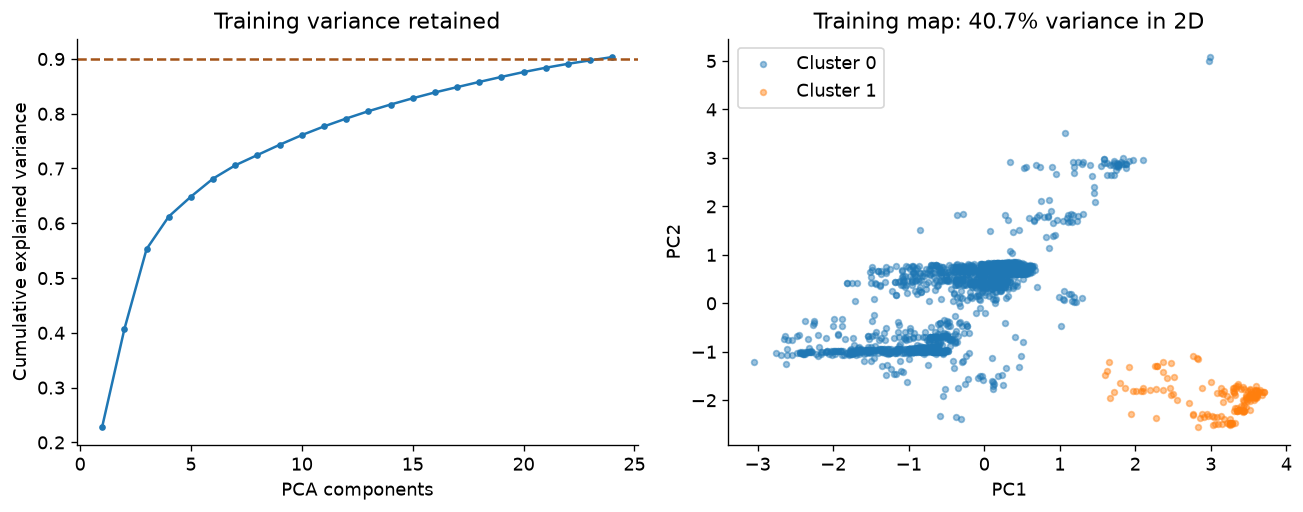

PCA in the supervised ablation was fitted independently within each training fold.


In [4]:
prep,pca,km,variance,cluster_quality,stability,profiles,cluster_examples,coords,unsup=unsupervised_analysis(train,OUT)
display(pd.DataFrame([unsup]).T)
display(cluster_quality.round(3)); display(stability.round(3))
display(profiles.round(3)); display(cluster_examples)
loadings=pd.read_csv(OUT/'pca_loadings.csv',index_col=0)
for pc in ['PC1','PC2']:
    display(loadings.loc[loadings[pc].abs().nlargest(6).index,[pc]])
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
axes[0].plot(variance.component,variance.cumulative,marker='o',markersize=3)
axes[0].axhline(.9,color='#A45419',linestyle='--')
axes[0].set(xlabel='PCA components',ylabel='Cumulative explained variance',title='Training variance retained')
for c,g in coords.groupby('cluster'):
    axes[1].scatter(g.PC1,g.PC2,s=12,alpha=.45,label=f'Cluster {c}')
axes[1].set(xlabel='PC1',ylabel='PC2',title=f'Training map: {unsup["variance_2d"]:.1%} variance in 2D')
axes[1].legend();fig.tight_layout();fig.savefig(FIG/'pca_clusters.png',bbox_inches='tight');plt.show()
models['SVM + PCA']=pca_svm
fold_records.extend(fixed_cv('SVM + PCA',pca_svm,train,folds))
print('PCA in the supervised ablation was fitted independently within each training fold.')

## 5. MLP learning check and best-earlier reference
**Architecture:** input dimension determined by train-fitted encoding; hidden layers **64 and 32**, ReLU activation, binary logistic output. Adam, learning rate 0.001, batch size 64, L2 alpha 0.01, seed 42, balanced sample weights. A compact network is appropriate for only 323 training positives.

Every fit creates an internal stratified 80/20 split from the supplied training rows. Its preprocessor fits the internal fitting subset only. We plot class-balanced log loss and positive F1 on both fitting and validation subsets. Training stops after 20 epochs without validation-loss improvement of at least 0.0001, or at 180 epochs. The best validation-loss epoch determines duration. A fresh pipeline then fits preprocessing on all supplied training rows and retrains for that duration. This uses all outer-training rows while keeping outer validation/test labels out of epoch selection.

Learning curves below belong to the full-training calibration split, not the holdout. The CV scores include their own independent internal validation and retraining. The same architecture and stopping policy apply everywhere. Check for a widening train/validation gap, a plateau, and whether the cap was reached. Better training loss alone is not evidence of better generalisation.

Best earlier reference chosen on training CV: Random Forest


,0
best_epoch,9
stopped_epoch,29
stop_reason,validation plateau
best_validation_loss,0.621108
calibration_fit_rows,1496
calibration_validation_rows,375
refit_rows,1871
best_earlier_reference,Random Forest
input_dimension,77
parameter_count,7105


,fold,f1,best_epoch,stopped_epoch
50,1,0.390000,8.0,28.0
51,2,0.384279,9.0,29.0
52,3,0.377880,9.0,29.0
53,4,0.362869,5.0,25.0
54,5,0.355556,7.0,27.0


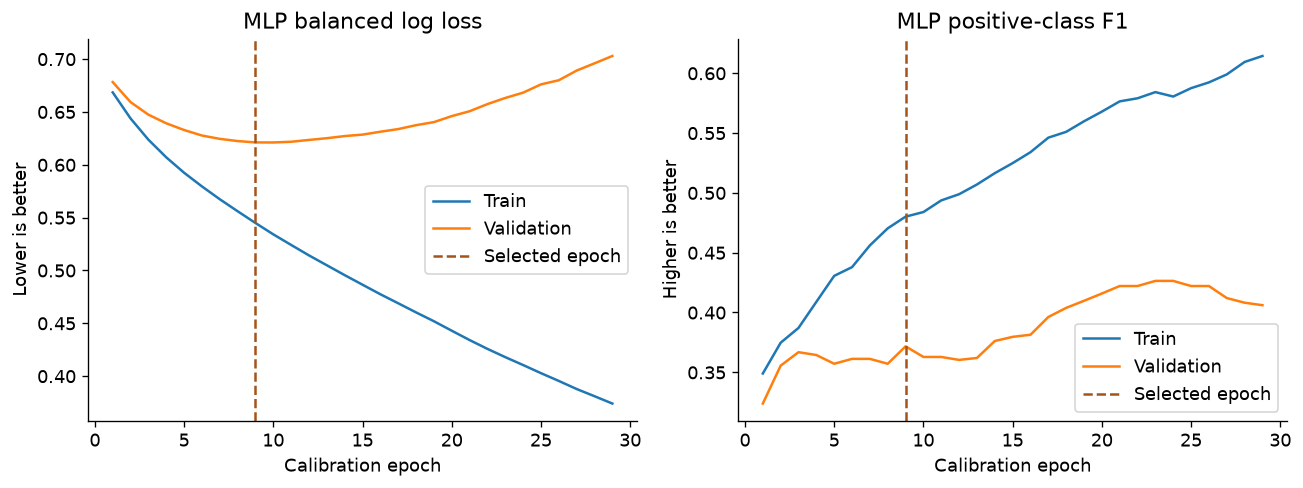

In [5]:
def cv_table(records):
    frame=pd.DataFrame(records)
    metrics=['f1','precision','recall','roc_auc','average_precision','balanced_accuracy','accuracy']
    rows=[]
    for name,g in frame.groupby('model',sort=False):
        row={'model':name}
        for metric in metrics:
            row['cv_'+metric+'_mean']=g[metric].mean()
            row['cv_'+metric+'_sd']=g[metric].std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)
earlier=cv_table(fold_records)
best_earlier=earlier[~earlier.model.str.startswith('Dummy')].sort_values(
    ['cv_f1_mean','cv_roc_auc_mean','model'],ascending=[False,False,True]).iloc[0]['model']
print('Best earlier reference chosen on training CV:',best_earlier)
models['MLP']=mlp
fold_records.extend(fixed_cv('MLP',mlp,train,folds))
mlp.fit(train[FEATURES],train.high_rated)
history=pd.DataFrame(mlp.history_)
history.to_csv(OUT/'mlp_learning.csv',index=False)
mlp_check={'best_epoch':mlp.best_epoch_,'stopped_epoch':mlp.stopped_epoch_,
           'stop_reason':mlp.stop_reason_,'best_validation_loss':mlp.best_validation_loss_,
           'calibration_fit_rows':mlp.calibration_train_size_,
           'calibration_validation_rows':mlp.calibration_validation_size_,
           'refit_rows':len(train),'best_earlier_reference':best_earlier,
           'input_dimension':mlp.model_.n_features_in_,
           'parameter_count':sum(a.size for a in mlp.model_.coefs_)+sum(a.size for a in mlp.model_.intercepts_)}
(OUT/'mlp_check.json').write_text(json.dumps(mlp_check,indent=2))
display(pd.DataFrame([mlp_check]).T)
display(pd.DataFrame(fold_records).query('model == "MLP"')[['fold','f1','best_epoch','stopped_epoch']])
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
for field,label in [('train_balanced_log_loss','Train'),('validation_balanced_log_loss','Validation')]:
    axes[0].plot(history.epoch,history[field],label=label)
for field,label in [('train_f1','Train'),('validation_f1','Validation')]:
    axes[1].plot(history.epoch,history[field],label=label)
for ax in axes:
    ax.axvline(mlp.best_epoch_,color='#A45419',linestyle='--',label='Selected epoch')
    ax.set_xlabel('Calibration epoch');ax.legend()
axes[0].set(title='MLP balanced log loss',ylabel='Lower is better')
axes[1].set(title='MLP positive-class F1',ylabel='Higher is better')
fig.tight_layout();fig.savefig(FIG/'mlp_learning.png',bbox_inches='tight');plt.show()

## 6. Selection freeze and one fair comparison
Before evaluating any Endterm test predictions, save the training-only model selection. The comparison includes both baselines, all Midterm models, fixed and tuned ensembles, the PCA ablation and MLP. Tuned-family CV values are nested outer estimates. Fixed models and MLP use the same outer folds. All spreads are sample SD across five outer folds.

The tuned final parameters may differ between outer folds, which is expected: nested CV evaluates a search procedure, not one fixed parameter tuple. The final 5-fold search on full train supplies the deployed settings. Scores remain uncertain on this small, imbalanced cohort.

In [6]:
cv_summary=cv_table(fold_records)
ranking=cv_summary[~cv_summary.model.str.startswith('Dummy')].sort_values(
    ['cv_f1_mean','cv_roc_auc_mean','model'],ascending=[False,False,True])
winner=ranking.iloc[0]['model']
decision={'selected_model':winner,'best_earlier_reference':best_earlier,
          'selection_metric':'Mean outer training CV positive-class F1',
          'test_used_for_selection':False,'searches':search_details,
          'target_threshold':8,'split_sha256':continuity['split_sha256']}
(OUT/'selection_before_test.json').write_text(json.dumps(decision,indent=2))
pd.DataFrame(fold_records).to_csv(OUT/'cv_fold_scores.csv',index=False)
cv_summary.to_csv(OUT/'cv_summary.csv',index=False)
display(cv_summary[['model','cv_f1_mean','cv_f1_sd','cv_roc_auc_mean']].round(3))
print('Selected before Endterm test evaluation:',winner)

,model,cv_f1_mean,cv_f1_sd,cv_roc_auc_mean
0,Dummy majority,0.000,0.000,0.500
1,Dummy stratified,0.155,0.034,0.492
2,Decision Tree,0.361,0.013,0.663
3,KNN,0.147,0.031,0.684
4,SVM,0.389,0.017,0.718
5,Forest fixed,0.391,0.019,0.702
6,Boosting fixed,0.352,0.027,0.651
7,Random Forest,0.401,0.025,0.718
8,Gradient Boosting,0.398,0.023,0.718
9,SVM + PCA,0.395,0.016,0.702


Selected before Endterm test evaluation: Random Forest


Final fit and held-out evaluation: Dummy majority


Final fit and held-out evaluation: Dummy stratified


Final fit and held-out evaluation: Decision Tree


Final fit and held-out evaluation: KNN


Final fit and held-out evaluation: SVM


Final fit and held-out evaluation: Forest fixed


... (3 outputs left out)

Final fit and held-out evaluation: Gradient Boosting


Final fit and held-out evaluation: SVM + PCA


Final fit and held-out evaluation: MLP


,model,cv_f1_mean,cv_f1_sd,test_f1,test_roc_auc,test_precision,test_recall,test_accuracy
0,Dummy majority,0.000,0.000,0.000,0.500,0.000,0.000,0.827
1,Dummy stratified,0.155,0.034,0.150,0.488,0.152,0.148,0.709
2,Decision Tree,0.361,0.013,0.300,0.563,0.199,0.605,0.511
3,KNN,0.147,0.031,0.231,0.647,0.522,0.148,0.829
4,SVM,0.389,0.017,0.340,0.643,0.256,0.506,0.660
5,Forest fixed,0.391,0.019,0.335,0.628,0.242,0.543,0.626
6,Boosting fixed,0.352,0.027,0.262,0.583,0.196,0.395,0.615
7,Random Forest,0.401,0.025,0.332,0.629,0.244,0.519,0.639
8,Gradient Boosting,0.398,0.023,0.322,0.639,0.231,0.531,0.613
9,SVM + PCA,0.395,0.016,0.305,0.626,0.228,0.457,0.639


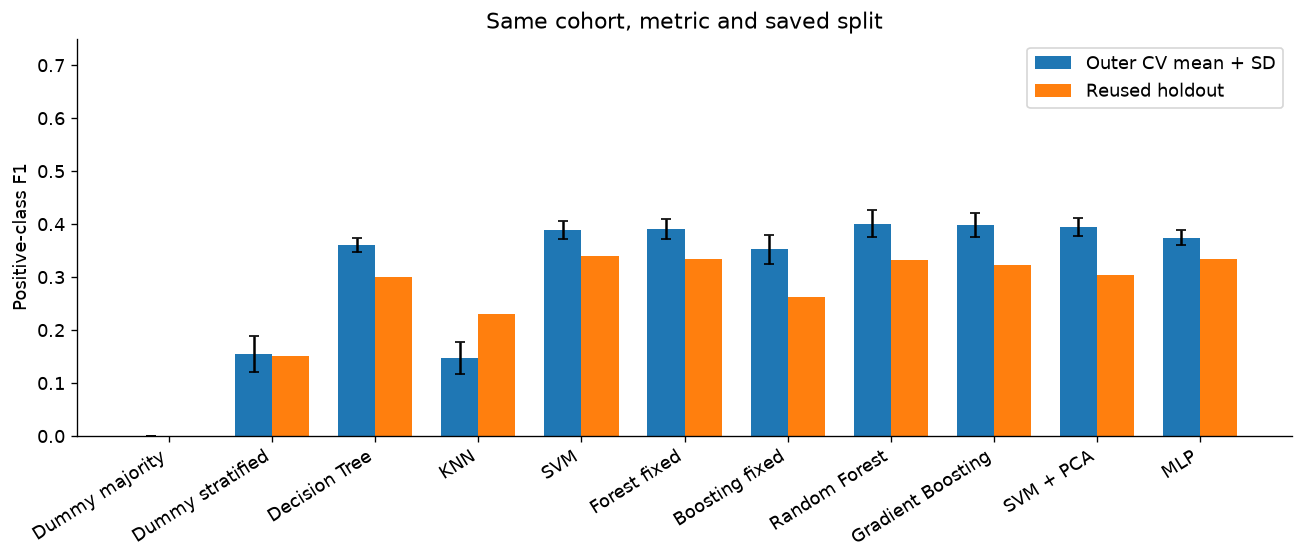

,model,original_cv_f1,current_cv_f1,delta,test_f1_unchanged
0,Dummy majority,0.000000,0.000000,0.000000,True
1,Dummy stratified,0.154806,0.154806,0.000000,True
2,Decision Tree,0.360689,0.360689,0.000000,True
3,KNN,0.157129,0.147306,-0.009823,True
4,SVM,0.389240,0.389240,0.000000,True


All Midterm test F1 values reproduce. KNN CV difference is disclosed below.


In [7]:
fitted={}; predicted_by_model={}; test_records=[]
X_test=test[FEATURES]; y_test=test.high_rated
for name,model in models.items():
    print('Final fit and held-out evaluation:',name,flush=True)
    fitted[name]=clone(model).fit(train[FEATURES],train.high_rated)
    predicted=fitted[name].predict(X_test)
    ranking_scores=positive_scores(fitted[name],X_test)
    predicted_by_model[name]=predicted
    test_records.append({'model':name,**{'test_'+k:v for k,v in scores(y_test,predicted,ranking_scores).items()}})
results=cv_summary.merge(pd.DataFrame(test_records),on='model',validate='one_to_one')
results.to_csv(OUT/'model_comparison.csv',index=False)
display(results[['model','cv_f1_mean','cv_f1_sd','test_f1','test_roc_auc','test_precision','test_recall','test_accuracy']].round(3))
fig,ax=plt.subplots(figsize=(11,4.8))
x=np.arange(len(results));ax.bar(x-.18,results.cv_f1_mean,.36,yerr=results.cv_f1_sd,capsize=3,label='Outer CV mean + SD')
ax.bar(x+.18,results.test_f1,.36,label='Reused holdout')
ax.set(xticks=x,xticklabels=results.model,ylabel='Positive-class F1',ylim=(0,.75),title='Same cohort, metric and saved split')
plt.setp(ax.get_xticklabels(),rotation=32,ha='right');ax.legend();fig.tight_layout()
fig.savefig(FIG/'model_comparison.png',bbox_inches='tight');plt.show()
joblib.dump(fitted[winner],ROOT/'models/endterm_model.joblib')
# Check continuity against original results. KNN has exact-distance ties.
reproduction=[]
for old in midterm['models']:
    new=results[results.model.eq(old['model'])].iloc[0]
    assert np.isclose(new.test_f1,old['test_f1'],atol=1e-12)
    delta=float(new.cv_f1_mean-old['cv_f1_mean'])
    if old['model'] != 'KNN': assert np.isclose(delta,0,atol=1e-12)
    reproduction.append({'model':old['model'],'original_cv_f1':old['cv_f1_mean'],'current_cv_f1':new.cv_f1_mean,'delta':delta,'test_f1_unchanged':True})
reproduction=pd.DataFrame(reproduction)
reproduction.to_csv(OUT/'midterm_reproduction.csv',index=False);display(reproduction.round(6))
print('All Midterm test F1 values reproduce. KNN CV difference is disclosed below.')

## 7. Confusion matrices, errors across models and cluster diagnostics
**Numerical continuity note:** Endterm fixes numerical-library threads to one for reproducibility. Original KNN CV F1 was 0.157129; with one thread it is 0.147306. A controlled rerun with the original default thread policy reproduces 0.157129. In fold 1, 172 of 375 validation rows have tied 15th/16th neighbour distances (tolerance 1e-12). Floating-point distance kernels can break those ties differently. The data, labels, k=15 and saved folds are unchanged. All Midterm test F1 values, and the other models' CV F1 values, reproduce. This numerical variation does not affect the Midterm best model or Endterm selection.

Read confusion matrices as actual rows, predicted columns. False positives are lower-rated shows incorrectly shortlisted. False negatives are high-rated shows missed. The error table compares real shows across all learned model families, including errors that new methods repair or introduce. Selection of examples follows the saved predictions, not manual relabelling.

SVM margins are signed decision scores, not probabilities. Other models' probability scores are uncalibrated. A rating of 7.9 and one of 8.0 have different labels despite their closeness. Error explanations are observational hypotheses, not proven causes. We do not change models based on these test diagnostics.

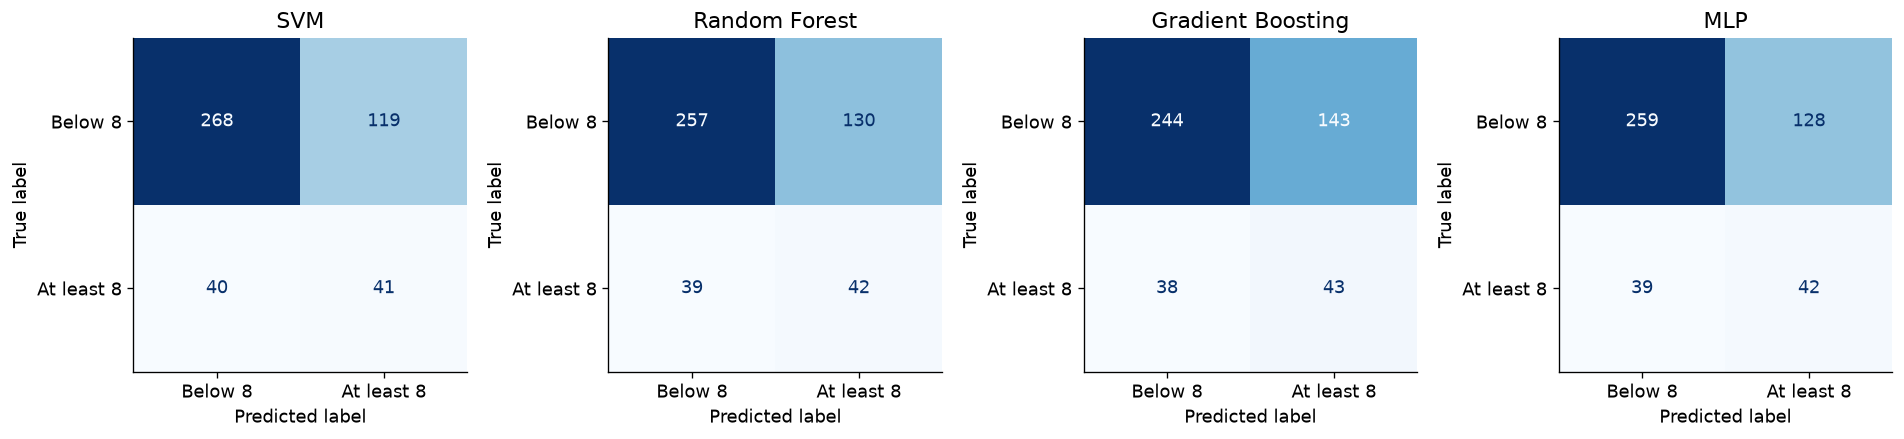

,model,TN,FP,FN,TP
0,SVM,268,119,40,41
1,Random Forest,257,130,39,42
2,Gradient Boosting,244,143,38,43
3,MLP,259,128,39,42
4,Dummy majority,387,0,81,0
5,Dummy stratified,320,67,69,12
6,Decision Tree,190,197,32,49
7,KNN,376,11,69,12
8,Forest fixed,249,138,37,44
9,Boosting fixed,256,131,49,32


**Decision Tree:** 197 false shortlist entries and 32 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

**KNN:** 11 false shortlist entries and 69 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

**SVM:** 119 false shortlist entries and 40 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

**Random Forest:** 130 false shortlist entries and 39 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

**Gradient Boosting:** 143 false shortlist entries and 38 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

**MLP:** 128 false shortlist entries and 39 missed high-rated series. Compare these costs alongside precision/recall in the shared table.

,name,rating,high_rated,Decision Tree,KNN,SVM,Random Forest,Gradient Boosting,MLP,genres,network
0,Person of Interest,8.8,1,1,0,1,0,0,0,"[""Action"", ""Crime"", ""Science-Fiction""]",CBS
5,Hawaii Five-0,7.7,0,1,0,1,1,0,0,"[""Action"", ""Crime"", ""Drama""]",CBS
6,Vikings,8.6,1,1,0,1,0,1,1,"[""Action"", ""Drama"", ""History""]",History
10,NCIS: New Orleans,7.5,0,1,0,1,1,0,0,"[""Action"", ""Crime"", ""Drama""]",CBS
25,Salem,6.9,0,1,0,1,0,1,0,"[""Drama"", ""Supernatural"", ""Thriller""]",NewsNation
34,Revolution,7.6,0,1,0,1,0,0,1,"[""Action"", ""Adventure"", ""Science-Fiction""]",NBC
43,Community,8.3,1,0,0,0,0,0,0,"[""Comedy""]",Unknown
70,The Prisoner,6.9,0,1,0,1,1,1,1,"[""Drama"", ""Mystery"", ""Science-Fiction""]",AMC
96,Rules of Engagement,8.0,1,0,0,0,0,0,0,"[""Comedy"", ""Romance""]",CBS
217,Touching Evil,7.1,0,1,1,1,1,1,1,"[""Crime"", ""Drama"", ""Thriller""]",USA Network


,cluster,model,test_rows,positive,F1,FP,FN
0,0,SVM,438,76,0.335,108,39
1,0,Random Forest,438,76,0.326,119,38
2,1,SVM,30,5,0.400,11,1
3,1,Random Forest,30,5,0.400,11,1


Cluster assignments use training-fitted PCA/K-Means. Group scores are descriptive and may be unstable with few positives. Seed ARI measures initialisation agreement, not proof of real categories.

In [8]:
focus=list(dict.fromkeys(['SVM','Random Forest','Gradient Boosting','MLP',winner]))
matrices={}; count_rows=[]
fig,axes=plt.subplots(1,len(focus),figsize=(4*len(focus),3.8))
for ax,name in zip(np.atleast_1d(axes),focus):
    cm=confusion_matrix(y_test,predicted_by_model[name],labels=[0,1]);matrices[name]=cm.tolist()
    tn,fp,fn,tp=cm.ravel()
    count_rows.append({'model':name,'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
    ConfusionMatrixDisplay(cm,display_labels=['Below 8','At least 8']).plot(ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(name)
for name in models:
    if name not in matrices:
        cm=confusion_matrix(y_test,predicted_by_model[name],labels=[0,1]);matrices[name]=cm.tolist()
        tn,fp,fn,tp=cm.ravel()
        count_rows.append({'model':name,'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
fig.tight_layout();fig.savefig(FIG/'confusion_matrices.png',bbox_inches='tight');plt.show()
counts=pd.DataFrame(count_rows);display(counts);counts.to_csv(OUT/'error_counts.csv',index=False)
for name in ['Decision Tree','KNN','SVM','Random Forest','Gradient Boosting','MLP']:
    row=counts[counts.model.eq(name)].iloc[0]
    display(Markdown(f'**{name}:** {row.FP} false shortlist entries and {row.FN} missed high-rated series. Compare these costs alongside precision/recall in the shared table.'))
audit=test[['show_id','name','rating','high_rated','genres','premiere_year','runtime_minutes','network','source_url']].copy()
for name,pred in predicted_by_model.items(): audit[name]=pred
audit['wrong_models']=(audit[list(predicted_by_model)].to_numpy()!=y_test.to_numpy()[:,None]).sum(axis=1)
audit.to_csv(OUT/'predictions_all_models.csv',index=False)
original_ids=midterm['examples']
chosen=[int(r['show_id']) for r in original_ids if r['outcome'] in ['False positive','False negative']]
svm_wrong=audit.SVM.ne(audit.high_rated);best_wrong=audit[winner].ne(audit.high_rated)
for mask in [svm_wrong & ~best_wrong,~svm_wrong & best_wrong,svm_wrong & best_wrong]:
    chosen.extend(audit.loc[mask].sort_values('show_id').head(2).show_id.tolist())
examples=audit[audit.show_id.isin(chosen)].sort_values('show_id')
examples.to_csv(OUT/'error_examples.csv',index=False)
display(examples[['name','rating','high_rated','Decision Tree','KNN','SVM','Random Forest','Gradient Boosting','MLP','genres','network']])
test_clusters=km.predict(pca.transform(prep.transform(X_test)))
group_rows=[]
for c in sorted(set(test_clusters)):
    ids=np.flatnonzero(test_clusters==c)
    for name in ['SVM',winner]:
        pred=predicted_by_model[name][ids];actual=y_test.iloc[ids].to_numpy()
        cm=confusion_matrix(actual,pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
        group_rows.append({'cluster':int(c),'model':name,'test_rows':len(ids),'positive':int(actual.sum()),
                           'F1':f1_score(actual,pred,zero_division=0),'FP':int(fp),'FN':int(fn)})
cluster_errors=pd.DataFrame(group_rows)
cluster_errors.to_csv(OUT/'cluster_errors.csv',index=False);display(cluster_errors.round(3))
display(Markdown('Cluster assignments use training-fitted PCA/K-Means. Group scores are descriptive and may be unstable with few positives. Seed ARI measures initialisation agreement, not proof of real categories.'))

## 8. Conclusions, remaining limitations and Final source plan
The measured answer and before/after evidence appear below. A model with higher training CV F1 can still have lower test F1. We retain the declared selection rule and report disagreements. Balanced weighting can improve recall while increasing false positives. The MLP can overfit with few minority examples even if its training loss falls.

**Remaining limitations:** a finite early-index cohort of rated English scripted series, subjective scores with no vote counts, hard 8/10 boundary, current channel metadata instead of verified release-time features, related franchises across a random split, and a reused holdout. Nested tuning reduces selection bias in CV, but does not remove sample bias or prove future-release performance. The 2D PCA map omits variance and unsupervised groups are sensitive to feature representation.

**Final source:** the existing `plot_summary` field from the same TVmaze API snapshot. Every cleaned object has text; join by `show_id`, so no new labels, row selection or split changes are needed. The source's public API and CC BY-SA 4.0 terms allow reuse with attribution and ShareAlike for the data. No private user data are needed.

**Feasible Final experiment:** train-only TF-IDF (unigrams/bigrams, limited vocabulary, regularised linear classifier), then metadata+text feature union. Fit vocabulary/IDF only inside training folds, tune regularisation on training CV, compare metadata-only, text-only and combined variants using positive F1, precision/recall and ranking on identical test IDs. Plot themes may describe content absent from channel/runtime metadata, but improvement is a hypothesis. Retain the best training-selected method even if its test score falls. Build a local series-shortlist app with clear score limitations and a report. For genuinely future claims, collect a separate later temporal cohort after the course benchmark, rather than repurposing the test set for tuning.

In [9]:
selected=results[results.model.eq(winner)].iloc[0]
svm=results[results.model.eq('SVM')].iloc[0]
network=results[results.model.eq('MLP')].iloc[0]
earlier=results[results.model.eq(best_earlier)].iloc[0]
conclusion=(f'Training CV selected {winner}. Its test F1 is {selected.test_f1:.3f}, '
            f'compared with Midterm SVM {svm.test_f1:.3f} (difference {selected.test_f1-svm.test_f1:+.3f}). '
            f'MLP outer CV F1 is {network.cv_f1_mean:.3f}; best earlier {best_earlier} is {earlier.cv_f1_mean:.3f}. '
            f'Test precision {selected.test_precision:.1%}, recall {selected.test_recall:.1%}. '
            'Metadata show limited predictive association, not a reliable standalone recommendation or a causal explanation.')
display(Markdown(conclusion))
before_after=[]
for fixed,tuned in [('Forest fixed','Random Forest'),('Boosting fixed','Gradient Boosting'),('SVM','SVM + PCA')]:
    a=results[results.model.eq(fixed)].iloc[0];b=results[results.model.eq(tuned)].iloc[0]
    before_after.append({'change':fixed+' to '+tuned,'before_cv_f1':a.cv_f1_mean,'after_cv_f1':b.cv_f1_mean,
                         'before_test_f1':a.test_f1,'after_test_f1':b.test_f1})
change_table=pd.DataFrame(before_after);display(change_table.round(3))
change_table.to_csv(OUT/'before_after.csv',index=False)
summary={'project':'Highly rated TV series','source':'TVmaze','collection_date':'2026-10-06',
         'continuity':continuity,'selected_model':winner,'best_earlier':best_earlier,
         'models':results.to_dict('records'),'searches':search_details,'unsupervised':unsup,
         'cluster_profiles':profiles.to_dict('records'),'cluster_examples':cluster_examples.to_dict('records'),
         'cluster_errors':cluster_errors.to_dict('records'),'mlp':mlp_check,'confusion_matrices':matrices,
         'error_counts':counts.to_dict('records'),'examples':examples.fillna('').to_dict('records'),
         'before_after':change_table.to_dict('records'),'conclusion':conclusion,
         'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                     'scikit-learn':sklearn.__version__}}
def finite_json(value):
    if isinstance(value,dict): return {k:finite_json(v) for k,v in value.items()}
    if isinstance(value,list): return [finite_json(v) for v in value]
    if isinstance(value,(float,np.floating)) and not np.isfinite(value): return None
    return value.item() if isinstance(value,np.generic) else value
summary=finite_json(summary)
(OUT/'experiment_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
print('Saved reproducible results, continuity evidence, errors and Endterm model.')

Training CV selected Random Forest. Its test F1 is 0.332, compared with Midterm SVM 0.340 (difference -0.008). MLP outer CV F1 is 0.374; best earlier Random Forest is 0.401. Test precision 24.4%, recall 51.9%. Metadata show limited predictive association, not a reliable standalone recommendation or a causal explanation.

,change,before_cv_f1,after_cv_f1,before_test_f1,after_test_f1
0,Forest fixed to Random Forest,0.391,0.401,0.335,0.332
1,Boosting fixed to Gradient Boosting,0.352,0.398,0.262,0.322
2,SVM to SVM + PCA,0.389,0.395,0.340,0.305


Saved reproducible results, continuity evidence, errors and Endterm model.


## 9. Contributions and tools
Project responsibilities:

| Participant | Responsibility |
|---|---|
| Bekzat Rashiduly | Data continuity, preprocessing, ensemble tuning, PCA/clustering, MLP, metrics, error analysis and technical conclusions |
| Gapar Galym | Presentation preparation, visual consistency and delivery of the project introduction |
| Aibek Galmbekov | Submission organisation, run instructions and presentation support |

All participants must understand the complete workflow and answer individual questions. This allocation describes responsibility for checking and defending the work, rather than independent authorship of every implementation step.

**Tools used:** Python, pandas, NumPy, scikit-learn, Matplotlib and Jupyter. **OpenAI Codex assisted with implementation, experiment execution, notebook text, slides and verification**, under Bekzat's direction. This disclosure follows the Endterm rubric's explicit requirement to name AI tools and their uses. Participants remain responsible for verifying the submitted work and explaining it independently.

### References
- TVmaze public API and licensing: https://www.tvmaze.com/api
- CC BY-SA 4.0: https://creativecommons.org/licenses/by-sa/4.0/
- scikit-learn ensembles: https://scikit-learn.org/stable/modules/ensemble.html
- PCA: https://scikit-learn.org/stable/modules/decomposition.html#pca
- Clustering: https://scikit-learn.org/stable/modules/clustering.html
- Neural networks: https://scikit-learn.org/stable/modules/neural_networks_supervised.html
